# Train nearest prefecture + weather → Low / Medium / High

First run `typhoon_nearest_prefecture_models.ipynb`. This notebook loads its reconstructed weather/prefecture file and trains Random Forest, CART, Gradient Boosting and SVM. **The classifiers are not LSTMs.**

The original label `Moderate` is displayed as `Medium`. The labels describe days before confirmed landfall; these event data do not validate ordinary daily typhoon occurrence risk.

## 1. Settings

In [1]:
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "training":
    ROOT = ROOT.parent
elif (ROOT / "Typhoon" / "training").is_dir():
    ROOT = ROOT / "Typhoon"
TRAINING_DIR = ROOT / "training"
EXPERIMENT_ID = "baseline_v1"
INPUT_FILE = TRAINING_DIR / "trained_models/nearest_prefecture" / EXPERIMENT_ID / "reconstructed_weather_prefecture.csv"
OUTPUT_DIR = TRAINING_DIR / "trained_models/risk" / EXPERIMENT_ID
LOG_DIR = TRAINING_DIR / "experiment_logs/risk" / EXPERIMENT_ID
SEED = 42
REMOVE_FEATURES = []  # e.g. ["rain_sum"]
MODEL_PARAMS = {
    "Random Forest": {"n_estimators": 300, "max_depth": None},
    "CART": {"max_depth": None},
    "Gradient Boosting": {"n_estimators": 100, "learning_rate": 0.1},
    "SVM": {"C": 1.0, "kernel": "rbf"},
}
OVERWRITE_OUTPUTS = False


## 2. Imports and data

In [2]:
# If needed:
# %pip install pandas numpy matplotlib scikit-learn joblib
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

if not INPUT_FILE.is_file():
    raise FileNotFoundError("Run the coordinate notebook first, or set INPUT_FILE to its reconstructed CSV.")
if OUTPUT_DIR.exists() and any(OUTPUT_DIR.iterdir()) and not OVERWRITE_OUTPUTS:
    raise FileExistsError("Choose a new OUTPUT_DIR, or set OVERWRITE_OUTPUTS=True for this experiment.")
if LOG_DIR.exists() and any(LOG_DIR.iterdir()) and not OVERWRITE_OUTPUTS:
    raise FileExistsError("Choose a new EXPERIMENT_ID, or enable OVERWRITE_OUTPUTS.")
LOG_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(INPUT_FILE, encoding="utf-8-sig")
required = {"risk", "intl_id", "landfall_event_id", "date", "split", "location_prediction_source"}
if not required.issubset(df.columns) or df.empty:
    raise ValueError("Use the reconstructed file from notebook 1, including its split/provenance columns.")
if df[list(required)].isna().any().any():
    raise ValueError("Labels, identifiers, dates, split and prediction provenance cannot be missing.")
df["date"] = pd.to_datetime(df["date"], errors="raise").dt.normalize()
if df.duplicated(["landfall_event_id", "date"]).any():
    raise ValueError("Duplicate event/date rows.")
labels = {"LOW": "Low", "MEDIUM": "Medium", "MODERATE": "Medium", "HIGH": "High"}
df["risk"] = df.risk.astype(str).str.upper().map(labels)
if df.risk.isna().any():
    raise ValueError("Risk labels must be Low, Medium/Moderate or High.")
print("Rows:", len(df))
display(df.risk.value_counts().rename("rows"))
display(df[["date", "nearest_prefecture", "risk", "split"]].head())


Rows: 75


risk
High      38
Medium    19
Low       18
Name: rows, dtype: int64

,date,nearest_prefecture,risk,split
0,2021-07-24,Wakayama,Low,train
1,2021-07-25,Tokyo,Medium,train
2,2021-07-26,Wakayama,High,train
3,2021-07-27,Wakayama,High,train
4,2021-08-05,Kagoshima,Low,test


## 3. Select only nearest prefecture and weather features

In [3]:
WEATHER = ['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'relative_humidity_2m_mean', 'relative_humidity_2m_max', 'relative_humidity_2m_min', 'dew_point_2m_mean', 'dew_point_2m_max', 'dew_point_2m_min', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'cloud_cover_mean', 'cloud_cover_max', 'cloud_cover_min', 'pressure_msl_mean', 'pressure_msl_max', 'pressure_msl_min', 'surface_pressure_mean', 'surface_pressure_max', 'surface_pressure_min', 'wind_speed_10m_mean', 'wind_speed_10m_max', 'wind_speed_10m_min', 'wind_gusts_10m_mean', 'wind_gusts_10m_max', 'wind_gusts_10m_min', 'wind_direction_10m_dominant', 'shortwave_radiation_sum']
FEATURES = ["nearest_prefecture", "year", "month", "day", "openmeteo_elevation"] + WEATHER
unknown = set(REMOVE_FEATURES) - set(FEATURES)
if unknown or "nearest_prefecture" in REMOVE_FEATURES:
    raise ValueError("Use valid feature names and keep nearest_prefecture.")
FEATURES = [c for c in FEATURES if c not in REMOVE_FEATURES]
missing = set(FEATURES) - set(df.columns)
if missing:
    raise ValueError(f"Missing classifier features: {sorted(missing)}")
NUMERIC = [c for c in FEATURES if c != "nearest_prefecture"]
df["year"], df["month"], df["day"] = df.date.dt.year, df.date.dt.month, df.date.dt.day
for col in NUMERIC:
    df[col] = pd.to_numeric(df[col], errors="raise")
if np.isinf(df[NUMERIC].to_numpy()).any():
    raise ValueError("Infinite weather values.")
if df.nearest_prefecture.isna().any():
    raise ValueError("Missing reconstructed nearest_prefecture.")
print("Classifier inputs:")
for name in FEATURES:
    print(" •", name)
print("Observed/predicted coordinates, storm attributes, IDs and risk labels are excluded from X.")


Classifier inputs:
 • nearest_prefecture
 • year
 • month
 • day
 • openmeteo_elevation
 • temperature_2m_mean
 • temperature_2m_max
 • temperature_2m_min
 • relative_humidity_2m_mean
 • relative_humidity_2m_max
 • relative_humidity_2m_min
 • dew_point_2m_mean
 • dew_point_2m_max
 • dew_point_2m_min
 • precipitation_sum
 • rain_sum
 • precipitation_hours
 • cloud_cover_mean
 • cloud_cover_max
 • cloud_cover_min
 • pressure_msl_mean
 • pressure_msl_max
 • pressure_msl_min
 • surface_pressure_mean
 • surface_pressure_max
 • surface_pressure_min
 • wind_speed_10m_mean
 • wind_speed_10m_max
 • wind_speed_10m_min
 • wind_gusts_10m_mean
 • wind_gusts_10m_max
 • wind_gusts_10m_min
 • wind_direction_10m_dominant
 • shortwave_radiation_sum
Observed/predicted coordinates, storm attributes, IDs and risk labels are excluded from X.


## 4. Keep the coordinate notebook’s storm split

In [4]:
if not set(df.split).issubset({"train", "test"}):
    raise ValueError("Unknown split label.")
train_df = df[df.split == "train"].copy()
test_df = df[df.split == "test"].copy()
if train_df.empty or test_df.empty:
    raise ValueError("Both train and test rows are required.")
assert set(train_df.intl_id).isdisjoint(test_df.intl_id), "Storm overlap between train/test."
assert train_df.location_prediction_source.eq("out_of_fold").all(), "Training locations must be out-of-fold."
assert test_df.location_prediction_source.eq("heldout").all(), "Test locations must be heldout."
if set(train_df.risk) != {"Low", "Medium", "High"}:
    raise ValueError("Training split must contain all three classes.")
X_train, X_test = train_df[FEATURES], test_df[FEATURES]
y_train, y_test = train_df.risk, test_df.risk
print(f"Train: {len(train_df)} rows | Test: {len(test_df)} rows | Shared storms: 0")
display(pd.concat([y_train.value_counts().rename("train"), y_test.value_counts().rename("test")], axis=1).fillna(0))


Train: 63 rows | Test: 12 rows | Shared storms: 0


,train,test
risk,,
High,32,6
Medium,16,3
Low,15,3


## 5. Preprocessing and classification models

In [5]:
numeric = Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)), ("scaler", StandardScaler())])
preprocessor = ColumnTransformer([
    ("numeric", numeric, NUMERIC),
    ("prefecture", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["nearest_prefecture"]),
])
models = {
    "Random Forest": RandomForestClassifier(random_state=SEED, class_weight="balanced", n_jobs=2, **MODEL_PARAMS["Random Forest"]),
    "CART": DecisionTreeClassifier(random_state=SEED, class_weight="balanced", **MODEL_PARAMS["CART"]),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED, **MODEL_PARAMS["Gradient Boosting"]),
    "SVM": SVC(random_state=SEED, class_weight="balanced", probability=True, **MODEL_PARAMS["SVM"]),
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## 6. Train, compare, and see confusion matrices
Use these heldout results for reporting. Repeatedly changing parameters based on the test results would turn the test set into a tuning set; use separate validation storms for tuning.


Training: Random Forest


              precision    recall  f1-score   support

         Low      0.500     0.333     0.400         3
      Medium      0.000     0.000     0.000         3
        High      0.375     0.500     0.429         6

    accuracy                          0.333        12
   macro avg      0.292     0.278     0.276        12
weighted avg      0.312     0.333     0.314        12



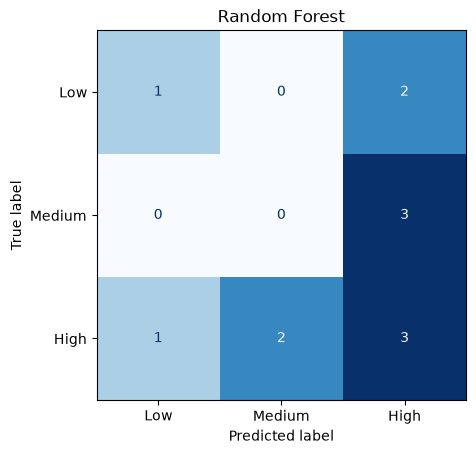


Training: CART
              precision    recall  f1-score   support

         Low      0.000     0.000     0.000         3
      Medium      0.500     0.333     0.400         3
        High      0.500     0.667     0.571         6

    accuracy                          0.417        12
   macro avg      0.333     0.333     0.324        12
weighted avg      0.375     0.417     0.386        12



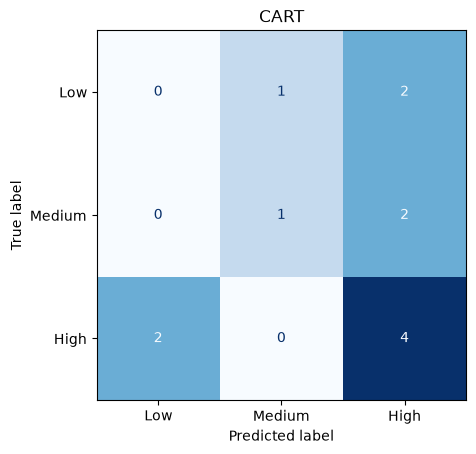


Training: Gradient Boosting


              precision    recall  f1-score   support

         Low      0.000     0.000     0.000         3
      Medium      0.500     0.667     0.571         3
        High      0.429     0.500     0.462         6

    accuracy                          0.417        12
   macro avg      0.310     0.389     0.344        12
weighted avg      0.339     0.417     0.374        12



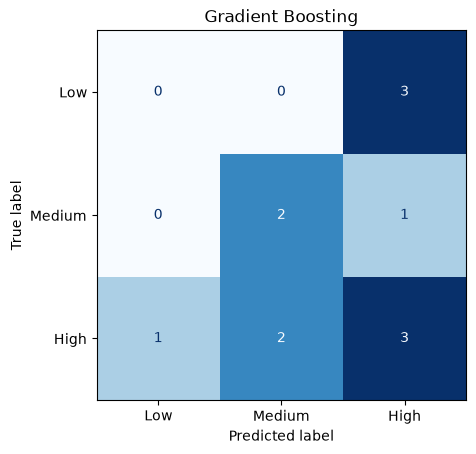


Training: SVM
              precision    recall  f1-score   support

         Low      0.200     0.333     0.250         3
      Medium      0.000     0.000     0.000         3
        High      0.429     0.500     0.462         6

    accuracy                          0.333        12
   macro avg      0.210     0.278     0.237        12
weighted avg      0.264     0.333     0.293        12



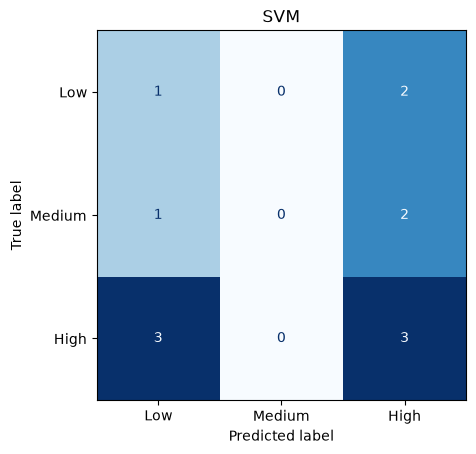

,Model,Accuracy,Balanced accuracy,Macro F1
0,Gradient Boosting,0.416667,0.388889,0.344322
1,CART,0.416667,0.333333,0.323810
2,Random Forest,0.333333,0.277778,0.276190
3,SVM,0.333333,0.277778,0.237179


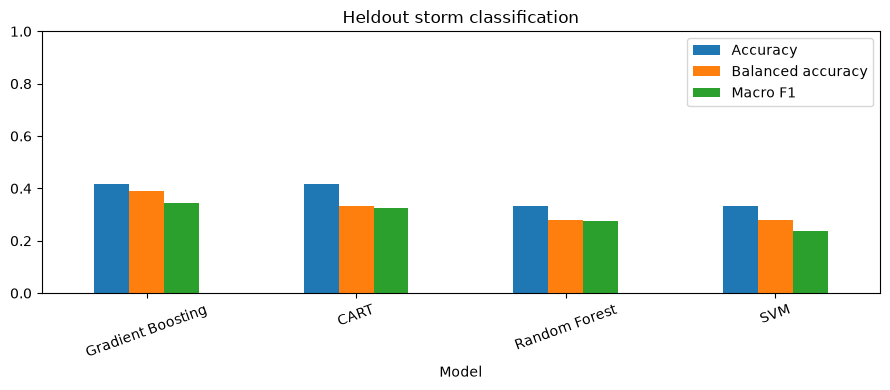

In [6]:
comparison = []
trained_models = {}
all_predictions = test_df[["date", "intl_id", "nearest_prefecture", "risk"]].copy()
CLASS_ORDER = ["Low", "Medium", "High"]
for name, estimator in models.items():
    print(f"\nTraining: {name}")
    classifier = Pipeline([("preprocessor", clone(preprocessor)), ("model", estimator)])
    classifier.fit(X_train, y_train)
    predicted = classifier.predict(X_test)
    trained_models[name] = classifier
    comparison.append({"Model": name, "Accuracy": accuracy_score(y_test, predicted),
                       "Balanced accuracy": balanced_accuracy_score(y_test, predicted),
                       "Macro F1": f1_score(y_test, predicted, labels=CLASS_ORDER, average="macro", zero_division=0)})
    print(classification_report(y_test, predicted, labels=CLASS_ORDER, digits=3, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=CLASS_ORDER, cmap="Blues", colorbar=False)
    plt.title(name)
    plt.savefig(LOG_DIR / (name.lower().replace(" ", "_") + "_confusion.png"), dpi=120, bbox_inches="tight")
    plt.show()
    filename = name.lower().replace(" ", "_")
    joblib.dump(classifier, OUTPUT_DIR / f"{filename}_model.joblib")
    all_predictions[name] = predicted

comparison = pd.DataFrame(comparison).sort_values("Balanced accuracy", ascending=False).reset_index(drop=True)
display(comparison)
comparison.set_index("Model")[["Accuracy", "Balanced accuracy", "Macro F1"]].plot.bar(figsize=(9, 4), ylim=(0, 1))
plt.title("Heldout storm classification")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(LOG_DIR / "model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()


## 7. Inspect one heldout prediction

In [7]:
MODEL_TO_VIEW = "Random Forest"  # choose any name from the comparison table
ROW_TO_VIEW = 0
if not 0 <= ROW_TO_VIEW < len(test_df):
    raise IndexError("ROW_TO_VIEW is outside the heldout test set.")
row = X_test.iloc[[ROW_TO_VIEW]]
classifier = trained_models[MODEL_TO_VIEW]
print("Date:", test_df.iloc[ROW_TO_VIEW]["date"].date())
print("Nearest prefecture:", row.nearest_prefecture.iloc[0])
print("Actual risk:", y_test.iloc[ROW_TO_VIEW])
print("Predicted risk:", classifier.predict(row)[0])
display(pd.Series(classifier.predict_proba(row)[0], index=classifier.classes_, name="probability").reindex(CLASS_ORDER).to_frame())


Date: 2021-08-05
Nearest prefecture: Kagoshima
Actual risk: Low
Predicted risk: High


,probability
Low,0.046667
Medium,0.048889
High,0.904444


## 8. Save comparison and prediction tables

In [8]:
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
all_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
train_df.to_csv(OUTPUT_DIR / "training_set.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
test_df.to_csv(OUTPUT_DIR / "testing_set.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
config = {"features": FEATURES, "classes": CLASS_ORDER, "model_parameters": MODEL_PARAMS,
          "input": str(INPUT_FILE), "test_storms": sorted(test_df.intl_id.astype(str).unique().tolist())}
(OUTPUT_DIR / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print("Saved classification models and results:", OUTPUT_DIR)
display(all_predictions.head(10))

(LOG_DIR / "experiment_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
comparison.to_csv(LOG_DIR / "model_comparison.csv", index=False)
print("Experiment logs:", LOG_DIR)


Saved classification models and results: /workspace/Project-Innovation/Typhoon/training/trained_models/risk/baseline_v1


,date,intl_id,nearest_prefecture,risk,Random Forest,CART,Gradient Boosting,SVM
4,2021-08-05,2109,Kagoshima,Low,High,High,High,High
5,2021-08-06,2109,Kagoshima,Medium,High,High,Medium,High
6,2021-08-07,2109,Kagoshima,High,Medium,High,Medium,Low
7,2021-08-08,2109,Kagoshima,High,High,High,High,High
8,2021-08-05,2109,Kagoshima,Low,High,High,High,High
9,2021-08-06,2109,Kagoshima,Medium,High,High,Medium,High
10,2021-08-07,2109,Kagoshima,High,Medium,High,Medium,Low
11,2021-08-08,2109,Kagoshima,High,Low,Low,Low,High
67,2024-08-08,2405,Okinawa,Low,Low,Medium,High,Low
68,2024-08-09,2405,Okinawa,Medium,High,Medium,High,Low


Experiment logs: /workspace/Project-Innovation/Typhoon/training/experiment_logs/risk/baseline_v1
